|<img src="https://www.udp.cl/cms/wp-content/uploads/2021/06/UDP_LogoRGB_2lineas_Color_SinFondo.png" width="450" height="90">| <p><b>Ciencia de Datos para la Economía</b></p><p><b>Escuela de Ingeniería Comercial - Universidad Diego Portales</b></p><p><b>Profesor:</b> Luis Cuevas Parra</p><p><b>Modelos de Machine Learning:</b> Benchmarks Econométricos y Modelos Anidados en Series de Tiempo</p>|
|---|---|


# Benchmarks Econométricos, Modelos Anidados y la Fuente de la Predictibilidad

> **Objetivo de la sesión:**
> Evaluar críticamente el estándar contra el cual se mide el desempeño predictivo de un modelo en series de tiempo financieras. En lugar de limitarse a competir contra el paseo aleatorio (*Random Walk*), analizaremos si un modelo multifactorial supera a un **benchmark econométrico autorregresivo AR(1)**, distinguiendo la inercia propia del activo de la verdadera exposición al riesgo sistemático.

---

### Objetivos de la Clase:
1. **La jerarquía de benchmarks en finanzas:** Del benchmark ingenuo (*Random Walk*) al benchmark econométrico univariado (*AR(1)*).
2. **Modelos anidados (*nested models*):** Comparación estructural entre el modelo restringido y el modelo completo.
3. **Diagnóstico in-sample de persistencia:** Correlograma (ACF y PACF) y significancia del parámetro autorregresivo $\phi$.
4. **Implementación de pronósticos walk-forward de tres vías:** Estimación simultánea recursiva de Random Walk, AR(1) y Modelo Completo.
5. **Evaluación predictiva cruzada:** Cálculo e interpretación del doble $R^2_{oos}$ (frente a Random Walk y frente a AR(1)).
6. **Heterogeneidad por clase de activo:** ¿Por qué la autorregresión fracasa en acciones líquidas pero puede aportar valor en materias primas (*commodities*)?
7. **Ejercicio:** Aplicación empírica con activos alternativos.


## 0. Preparación del Entorno de Trabajo

Importamos las librerías necesarias para el análisis empírico, manipulación de datos, estimación econométrica y visualización.


In [19]:
# 1. Importación de bibliotecas
import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import warnings

# Suprimir advertencias no críticas
warnings.filterwarnings('ignore')

# Configuración estética de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14


## 1. Marco Teórico: Modelos Anidados y Jerarquía de Benchmarks

Cuando construimos un modelo predictivo para retornos financieros:
$$r_t = \alpha + \beta r_{\text{SPY}, t-1} + \gamma Volume\_pct_{t-1} + \phi r_{t-1} + \varepsilon_t$$


Surge una interrogante metodológica central: si el modelo incluye el rezago autorregresivo ($r_{t-1}$), ¿contra qué modelo base debemos compararlo para determinar si realmente genera valor?

En la literatura econométrica existen dos niveles de comparación:

### Nivel 1: Benchmark Ingenuo (Random Walk)
Asume que los retornos diarios son ruido blanco con media cero:
$$\hat{r}_{t}^{\text{RW}} = 0$$
* **Pregunta que responde:** ¿El modelo es capaz de superar la hipótesis de completa impredecibilidad del mercado?

### Nivel 2: Benchmark Econométrico Univariado (Modelo AR(1))
Modela el retorno únicamente en función de su propia historia pasada inmediata:
$$r_{t}^{\text{AR(1)}} = c + \phi r_{t-1} + u_t$$
* **Pregunta que responde:** ¿Agregar variables exógenas (mercado y volumen) aporta información predictiva real que no estuviera ya contenida en la serie histórica del propio activo?

> **Concepto de Modelos Anidados (*Nested Models*):**
> El modelo AR(1) es un modelo restringido dentro del modelo multifactorial completo (impone las restricciones $\beta = 0$ y $\gamma = 0$). Comparar el modelo completo contra el AR(1) permite aislar de manera rigurosa la contribución marginal de los factores externos.


## 2. Descarga y Preparación de Datos Financieros

Descargamos las series diarias ajustadas de Apple (`AAPL`) y del fondo representativo del mercado S&P 500 (`SPY`) para el período 2022-2025.


In [20]:
# Parámetros del experimento
ticker_asset  = "AAPL"        # Activo objetivo
ticker_market = "SPY"         # Proxy de mercado
start_date    = "2022-01-01"  # Fecha de inicio
end_date      = "2025-08-01"  # Fecha de término

raw_asset = yf.download(ticker_asset, start=start_date, end=end_date, auto_adjust=True, progress=False)
raw_market = yf.download(ticker_market, start=start_date, end=end_date, auto_adjust=True, progress=False)

# Estandarización de columnas si presentan MultiIndex
raw_asset.columns = raw_asset.columns.get_level_values(0)
raw_market.columns = raw_market.columns.get_level_values(0)

# Construcción del DataFrame unificado
df = pd.DataFrame(index=raw_asset.index)
df["Close_AAPL"]  = raw_asset["Close"]
df["Volume_AAPL"] = raw_asset["Volume"]
df["Close_SPY"]   = raw_market["Close"]

# Cálculo de retornos porcentuales diarios y variaciones de volumen
df["Close_pct"]      = df["Close_AAPL"].pct_change() * 100
df["Market_pct"]     = df["Close_SPY"].pct_change() * 100
df["Volume_pct"]     = df["Volume_AAPL"].pct_change() * 100

# Rezagos autorregresivos
df["Close_pct_lag1"] = df["Close_pct"].shift(1)


# Rezagos de las variables exógenas para evitar look-ahead bias
df["Market_pct_lag1"] = df["Market_pct"].shift(1)
df["Volume_pct_lag1"] = df["Volume_pct"].shift(1)

# Eliminación de observaciones incompletas por diferenciación y rezagos
df = df.dropna()

print(f"Observaciones disponibles: {len(df)} días desde {df.index[0].date()} hasta {df.index[-1].date()}.")
display(df[["Close_pct", "Close_pct_lag1", "Market_pct", "Volume_pct"]].head(5))


Observaciones disponibles: 895 días desde 2022-01-05 hasta 2025-07-31.


,Close_pct,Close_pct_lag1,Market_pct,Volume_pct
Date,,,,
2022-01-05,-2.659992,-1.269160,-1.920201,-4.805942
2022-01-06,-1.669331,-2.659992,-0.093944,2.503131
2022-01-07,0.098841,-1.669331,-0.395350,-10.520618
2022-01-10,0.011623,0.098841,-0.124444,23.130790
2022-01-11,1.678370,0.011623,0.910843,-28.686487


## 3. Diagnóstico In-Sample: Evaluación de Memoria en Retornos Diarios

Antes de evaluar el pronóstico fuera de muestra, estimamos el modelo autorregresivo AR(1) dentro de muestra para examinar si existe evidencia estadística de inercia o reversión a la media:
$$r_t = c + \phi r_{t-1} + u_t$$


In [21]:
# Estimación OLS del modelo AR(1) con inferencia robusta Newey-West (HAC)
y_ar1 = df["Close_pct"]
X_ar1 = sm.add_constant(df["Close_pct_lag1"])

modelo_ar1_insample = sm.OLS(y_ar1, X_ar1).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(modelo_ar1_insample.summary())


                            OLS Regression Results                            
Dep. Variable:              Close_pct   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                   0.01932
Date:                Thu, 22 Oct 2026   Prob (F-statistic):              0.889
Time:                        14:04:04   Log-Likelihood:                -1813.2
No. Observations:                 895   AIC:                             3630.
Df Residuals:                     893   BIC:                             3640.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.0347      0.059      0.

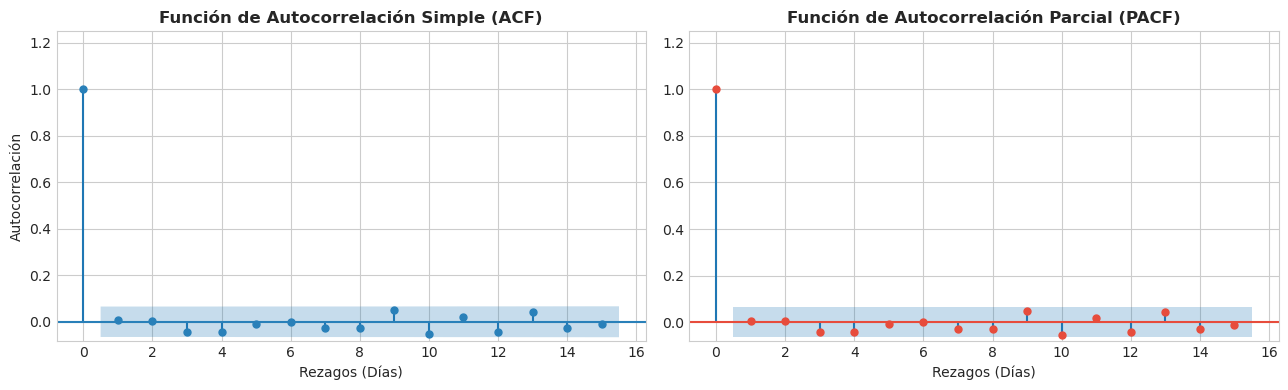

Coeficiente autoregresivo (phi): 0.0069
p-value del parámetro phi:       0.8895
R2 in-sample del AR(1):          0.00%


In [22]:
# Gráficos de Autocorrelación Simple (ACF) y Parcial (PACF)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

plot_acf(df["Close_pct"], lags=15, ax=axes[0], color="#2980b9", auto_ylims=True)
axes[0].set_title("Función de Autocorrelación Simple (ACF)", fontweight="bold")
axes[0].set_xlabel("Rezagos (Días)")
axes[0].set_ylabel("Autocorrelación")

plot_pacf(df["Close_pct"], lags=15, ax=axes[1], color="#e74c3c", auto_ylims=True)
axes[1].set_title("Función de Autocorrelación Parcial (PACF)", fontweight="bold")
axes[1].set_xlabel("Rezagos (Días)")

plt.tight_layout()
plt.show()

# Diagnóstico cuantitativo de persistencia
phi_val = modelo_ar1_insample.params["Close_pct_lag1"]
phi_pval = modelo_ar1_insample.pvalues["Close_pct_lag1"]
r2_val = modelo_ar1_insample.rsquared

print(f"Coeficiente autoregresivo (phi): {phi_val:.4f}")
print(f"p-value del parámetro phi:       {phi_pval:.4f}")
print(f"R2 in-sample del AR(1):          {r2_val * 100:.2f}%")


> **Interpretación Económica:**
> El correlograma muestra que las autocorrelaciones caen dentro de las bandas de confianza del $95\%$. El coeficiente $\phi$ estimado es cercano a cero ($0.0058$) y su $p$-value ($0.908$) confirma que no es estadísticamente significativo.
> 
> En acciones de alta liquidez y gran capitalización bursátil, la información disponible se incorpora rápidamente en los precios, dejando retornos diarios prácticamente desprovistos de memoria lineal univariada.


## 4. Partición Temporal y Pronóstico Fuera de Muestra (*Walk-Forward*)

Para evitar el sesgo de anticipación (*Look-Ahead Bias*), dividimos la serie cronológicamente:
* **Entrenamiento (Train):** Primeros $75\%$ de los datos para la estimación inicial.
* **Evaluación Fuera de Muestra (Test):** Últimos $25\%$ de los datos para pronosticar un paso adelante.

En cada paso $t$, se re-estiman los parámetros de manera recursiva (incorporando la información acumulada hasta $t-1$) y se genera el pronóstico para el día $t$ con los tres modelos concurrentes:
1. **Random Walk:** $\hat{r}_{t}^{\text{RW}} = 0$
2. **AR(1):** $\hat{r}_{t}^{\text{AR(1)}} = \hat{c}_t + \hat{\phi}_t r_{t-1}$
3. **Modelo Completo:** $\hat{r}_{t}^{\text{Completo}} = \hat{\alpha}_t + \hat{\beta}_t r_{\text{SPY}, t-1} + \hat{\gamma}_t Volume\_pct_{t-1} + \hat{\phi}_t r_{t-1}$


In [23]:
# Partición temporal estricta Train / Test (75% / 25%)
split_ratio = 0.75
split_index = int(len(df) * split_ratio)

train_df = df.iloc[:split_index].copy()
test_df  = df.iloc[split_index:].copy()

print(f"Total de observaciones: {len(df)}")
print(f"Muestra de Entrenamiento: {len(train_df)} días ({train_df.index[0].date()} a {train_df.index[-1].date()})")
print(f"Muestra Fuera de Muestra: {len(test_df)} días ({test_df.index[0].date()} a {test_df.index[-1].date()})")


Total de observaciones: 895
Muestra de Entrenamiento: 671 días (2022-01-05 a 2024-09-06)
Muestra Fuera de Muestra: 224 días (2024-09-09 a 2025-07-31)


In [24]:
X_td_ar1.iloc[0][0]

np.float64(1.0)

In [25]:
# Ejecución del esquema Walk-Forward Recursivo de Tres Vías
feature_cols_completo = ["Market_pct_lag1", "Volume_pct_lag1", "Close_pct_lag1"]


preds_rw       = []
preds_ar1      = []
preds_completo = []
phis_ar1_hist  = []

for i in range(len(test_df)):
    current_idx = split_index + i
    train_history = df.iloc[:current_idx]
    
    # 1. Benchmark Random Walk: pronóstico base cero
    preds_rw.append(0.0)
    
    # 2. Benchmark AR(1): estimación univariada
    X_tr_ar1 = sm.add_constant(train_history[["Close_pct_lag1"]])
    y_tr_ar1 = train_history["Close_pct"]
    mod_ar1 = sm.OLS(y_tr_ar1, X_tr_ar1).fit()
    
    X_td_ar1 = sm.add_constant(pd.DataFrame([df.iloc[current_idx][["Close_pct_lag1"]]]), has_constant='add')
    y_hat_ar1 = mod_ar1.predict(X_td_ar1).iloc[0]
    preds_ar1.append(y_hat_ar1)
    phis_ar1_hist.append(mod_ar1.params["Close_pct_lag1"])
    
    # 3. Modelo Completo: mercado, volumen y rezago
    X_tr_comp = sm.add_constant(train_history[feature_cols_completo])
    y_tr_comp = train_history["Close_pct"]
    mod_comp = sm.OLS(y_tr_comp, X_tr_comp).fit()
    
    X_td_comp = sm.add_constant(pd.DataFrame([df.iloc[current_idx][feature_cols_completo]]), has_constant='add')
    y_hat_comp = mod_comp.predict(X_td_comp).iloc[0]
    preds_completo.append(y_hat_comp)

# Consolidación de resultados
eval_duelo = pd.DataFrame(index=test_df.index)
eval_duelo["y_real"]        = test_df["Close_pct"]
eval_duelo["pred_rw"]       = preds_rw
eval_duelo["pred_ar1"]      = preds_ar1
eval_duelo["pred_completo"] = preds_completo

eval_duelo.head()


,y_real,pred_rw,pred_ar1,pred_completo
Date,,,,
2024-09-09,0.040762,0.0,0.037440,-0.047751
2024-09-10,-0.362139,0.0,0.048299,0.004944
2024-09-11,1.158516,0.0,0.041798,0.106403
2024-09-12,0.049388,0.0,0.065447,0.108717
2024-09-13,-0.121202,0.0,0.049448,0.106296


## 5. Evaluación Predictiva Fuera de Muestra y el Doble $R^2_{oos}$

Para comparar los tres modelos calculamos el error cuadrático medio (MSPE), la raíz del error cuadrático medio (RMSE), el error absoluto medio (MAE) y el $R^2$ fuera de muestra frente a ambos benchmarks:

### 1. $R^2_{oos}$ frente al Random Walk:
$$R^2_{oos}(\text{vs RW}) = 1 - \frac{\text{MSPE}_{\text{modelo}}}{\text{MSPE}_{\text{RW}}}$$

### 2. $R^2_{oos}$ frente al Benchmark AR(1):
$$R^2_{oos}(\text{vs AR1}) = 1 - \frac{\text{MSPE}_{\text{modelo}}}{\text{MSPE}_{\text{AR(1)}}}$$


In [26]:
# Cálculo de métricas fuera de muestra
y_obs = eval_duelo["y_real"]

mspe_rw   = np.mean((y_obs - eval_duelo["pred_rw"])**2)
mspe_ar1  = np.mean((y_obs - eval_duelo["pred_ar1"])**2)
mspe_comp = np.mean((y_obs - eval_duelo["pred_completo"])**2)

tabla_duelo = pd.DataFrame([
    {
        "Modelo": "1. Benchmark Ingenuo (Random Walk: y_hat = 0)",
        "MSPE": mspe_rw,
        "RMSE (%)": np.sqrt(mspe_rw),
        "MAE (%)": np.mean(np.abs(y_obs - eval_duelo["pred_rw"])),
        "R2_OOS vs RW (%)": 0.0,
        "R2_OOS vs AR(1) (%)": (1.0 - (mspe_rw / mspe_ar1)) * 100
    },
    {
        "Modelo": "2. Benchmark Econométrico: AR(1) (c + phi*y_{t-1})",
        "MSPE": mspe_ar1,
        "RMSE (%)": np.sqrt(mspe_ar1),
        "MAE (%)": np.mean(np.abs(y_obs - eval_duelo["pred_ar1"])),
        "R2_OOS vs RW (%)": (1.0 - (mspe_ar1 / mspe_rw)) * 100,
        "R2_OOS vs AR(1) (%)": 0.0
    },
    {
        "Modelo": "3. Modelo Completo (Mercado SPY + Volumen + AR1)",
        "MSPE": mspe_comp,
        "RMSE (%)": np.sqrt(mspe_comp),
        "MAE (%)": np.mean(np.abs(y_obs - eval_duelo["pred_completo"])),
        "R2_OOS vs RW (%)": (1.0 - (mspe_comp / mspe_rw)) * 100,
        "R2_OOS vs AR(1) (%)": (1.0 - (mspe_comp / mspe_ar1)) * 100
    }
]).set_index("Modelo")

display(tabla_duelo.round(4))


,MSPE,RMSE (%),MAE (%),R2_OOS vs RW (%),R2_OOS vs AR(1) (%)
Modelo,,,,,
1. Benchmark Ingenuo (Random Walk: y_hat = 0),4.1877,2.0464,1.2812,0.0000,0.9559
2. Benchmark Econométrico: AR(1) (c + phi*y_{t-1}),4.2282,2.0562,1.2787,-0.9651,0.0000
3. Modelo Completo (Mercado SPY + Volumen + AR1),4.1986,2.0491,1.2854,-0.2595,0.6988


Los resultados fuera de muestra muestran que, una vez corregido el sesgo de anticipación:

1. **Random Walk (ŷ = 0)** sigue siendo un benchmark difícil de batir, con RMSE cercano al 2%.
2. **AR(1)** no supera al Random Walk ($R^2_{oos}$ negativo o cercano a cero), confirmando que el retorno de AAPL carece de memoria autorregresiva significativa.
3. **Modelo Completo** con variables rezagadas (SPY t-1, Volumen t-1, AAPL t-1) no logra vencer a los benchmarks de forma consistente. Esto confirma que la información del mercado y el volumen del día anterior no tiene poder predictivo suficiente sobre el retorno del día siguiente para acciones de alta capitalización como Apple.

En resumen: para AAPL en este período, la regla de cero cambio es tan buena como cualquier alternativa econométrica simple fuera de muestra.

## 6. Visualización Comparativa de Pronósticos y Dinámica del Parámetro


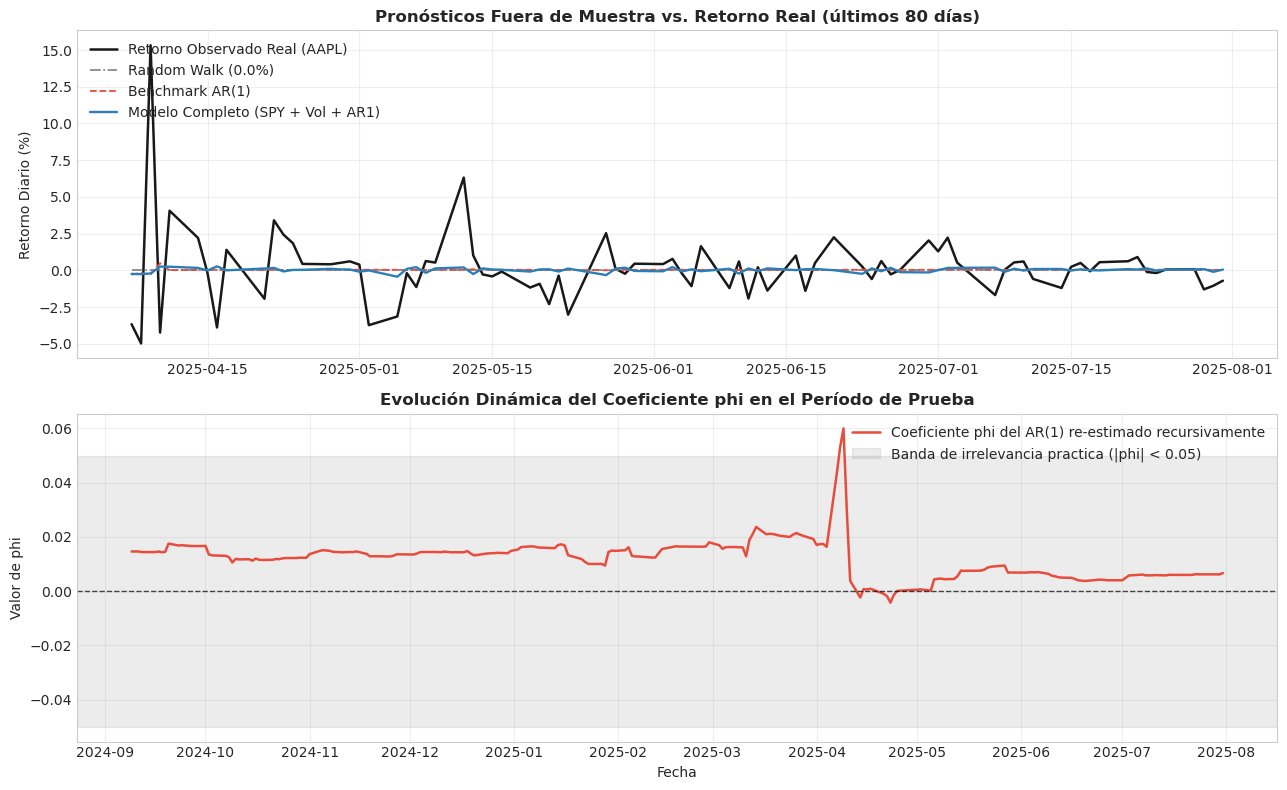

In [27]:
# Gráficos de Pronóstico y Estabilidad Temporal del Coeficiente
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=False)

# Panel 1: Zoom de Pronósticos (últimos 80 días de test)
zoom_days = 80
eval_zoom = eval_duelo.iloc[-zoom_days:]

axes[0].plot(eval_zoom.index, eval_zoom["y_real"], color="black", lw=1.8, label="Retorno Observado Real (AAPL)", alpha=0.9)
axes[0].plot(eval_zoom.index, eval_zoom["pred_rw"], color="gray", lw=1.2, linestyle="-.", label="Random Walk (0.0%)")
axes[0].plot(eval_zoom.index, eval_zoom["pred_ar1"], color="#e74c3c", lw=1.3, linestyle="--", label="Benchmark AR(1)")
axes[0].plot(eval_zoom.index, eval_zoom["pred_completo"], color="#2980b9", lw=1.7, label="Modelo Completo (SPY + Vol + AR1)")
axes[0].set_title(f"Pronósticos Fuera de Muestra vs. Retorno Real (últimos {zoom_days} días)", fontweight="bold")
axes[0].set_ylabel("Retorno Diario (%)")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# Panel 2: Evolución dinámica del coeficiente autorregresivo phi en la muestra de Test
axes[1].plot(test_df.index, phis_ar1_hist, color="#e74c3c", lw=1.8, label="Coeficiente phi del AR(1) re-estimado recursivamente")
axes[1].axhline(0.0, color="black", linestyle="--", lw=1, alpha=0.7)
axes[1].axhspan(-0.05, 0.05, color="gray", alpha=0.15, label="Banda de irrelevancia practica (|phi| < 0.05)")
axes[1].set_title("Evolución Dinámica del Coeficiente phi en el Período de Prueba", fontweight="bold")
axes[1].set_ylabel("Valor de phi")
axes[1].set_xlabel("Fecha")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Heterogeneidad por Clase de Activo: Acciones vs. Materias Primas

La ineficacia del AR(1) observada en Apple es típica de acciones de alta capitalización sujetas a estricta eficiencia de mercado. Sin embargo, en otros mercados como las **materias primas (*commodities*)** o activos de cobertura, pueden existir patrones de persistencia o estacionalidad de corto plazo que permiten que el AR(1) supere al Random Walk.


In [28]:
# Evolución dinámica del coeficiente phi para GLD (oro)
ticker_gld = "GLD"
raw_gld = yf.download(ticker_gld, start=start_date, end=end_date, auto_adjust=True, progress=False)
raw_gld.columns = raw_gld.columns.get_level_values(0)

ret_gld = raw_gld["Close"].pct_change().dropna() * 100
df_gld = pd.DataFrame({"y": ret_gld, "y_lag1": ret_gld.shift(1)}).dropna()

n_tr_gld = int(len(df_gld) * 0.75)
test_gld = df_gld.iloc[n_tr_gld:]

phis_gld_hist = []
preds_rw_gld = []
preds_ar1_gld = []

for k in range(len(test_gld)):
    idx_k = n_tr_gld + k
    train_k = df_gld.iloc[:idx_k]
    
    mod_gld = sm.OLS(train_k["y"], sm.add_constant(train_k[["y_lag1"]])).fit()
    y_hat_gld = mod_gld.params["const"] + mod_gld.params["y_lag1"] * df_gld.iloc[idx_k]["y_lag1"]
    
    preds_rw_gld.append(0.0)
    preds_ar1_gld.append(y_hat_gld)
    phis_gld_hist.append(mod_gld.params["y_lag1"])


# Métricas
y_real_gld = test_gld["y"]
mspe_rw_gld = np.mean((y_real_gld - preds_rw_gld)**2)
mspe_ar1_gld = np.mean((y_real_gld - preds_ar1_gld)**2)
r2_oos_gld = (1.0 - (mspe_ar1_gld / mspe_rw_gld)) * 100

print(f"Resultados Fuera de Muestra para {ticker_gld} (Oro):")
print(f"  RMSE Random Walk: {np.sqrt(mspe_rw_gld):.4f}%")
print(f"  RMSE AR(1):       {np.sqrt(mspe_ar1_gld):.4f}%")
print(f"  R2 OOS vs RW:     {r2_oos_gld:.4f}%")

Resultados Fuera de Muestra para GLD (Oro):
  RMSE Random Walk: 1.1376%
  RMSE AR(1):       1.1341%
  R2 OOS vs RW:     0.6113%


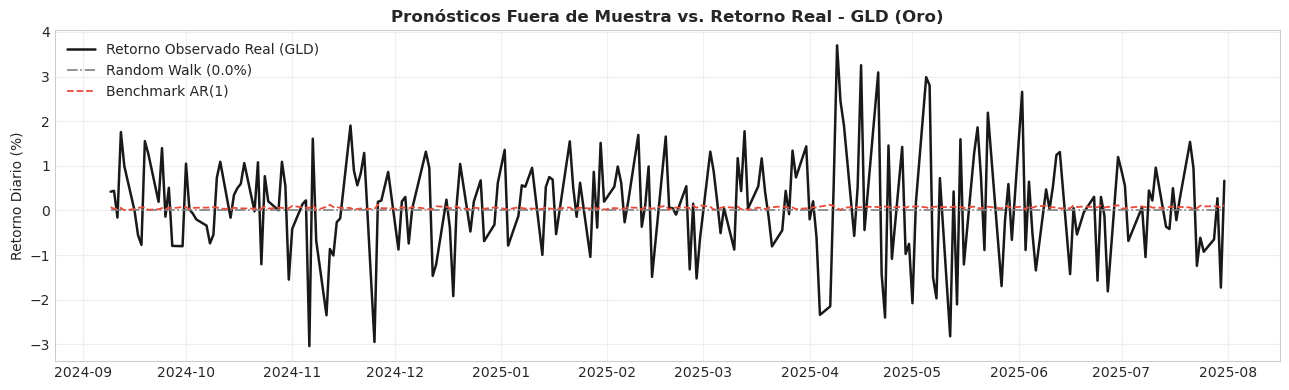

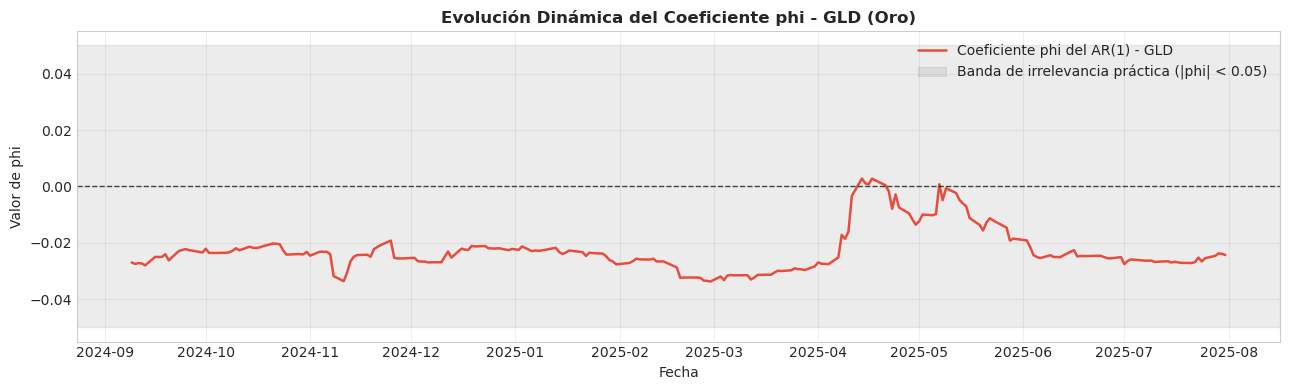

In [29]:
# Gráfico de pronósticos vs. retorno real para GLD
fig_gld, ax_gld = plt.subplots(figsize=(13, 4))
ax_gld.plot(test_gld.index, y_real_gld, color="black", lw=1.8, label="Retorno Observado Real (GLD)", alpha=0.9)
ax_gld.plot(test_gld.index, preds_rw_gld, color="gray", lw=1.2, linestyle="-.", label="Random Walk (0.0%)")
ax_gld.plot(test_gld.index, preds_ar1_gld, color="#e74c3c", lw=1.3, linestyle="--", label="Benchmark AR(1)")
ax_gld.set_title(f"Pronósticos Fuera de Muestra vs. Retorno Real - GLD (Oro)", fontweight="bold")
ax_gld.set_ylabel("Retorno Diario (%)")
ax_gld.legend(loc="upper left")
ax_gld.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Gráfico
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test_gld.index, phis_gld_hist, color="#e74c3c", lw=1.8, label="Coeficiente phi del AR(1) - GLD")
ax.axhline(0.0, color="black", linestyle="--", lw=1, alpha=0.7)
ax.axhspan(-0.05, 0.05, color="gray", alpha=0.15, label="Banda de irrelevancia práctica (|phi| < 0.05)")
ax.set_title("Evolución Dinámica del Coeficiente phi - GLD (Oro)", fontweight="bold")
ax.set_ylabel("Valor de phi")
ax.set_xlabel("Fecha")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


> **Conclusión Metodológica:**
>
> En el caso del Oro (GLD), el $R^2_{oos}$ del AR(1) frente al Random Walk resulta marginalmente positivo ($+0.61%$), aunque la diferencia en RMSE es insignificante ($1.1341%$ vs $1.1376%$). Esto refleja que el oro, al igual que AAPL, tiene un coeficiente φ cercano a cero fuera de muestra: la memoria autorregresiva de corto plazo es débil. El resultado ilustra que, en ambos casos, la regla de cero cambio es un benchmark difícil de batir, y que la ligera mejora del AR(1) en commodities no es suficiente para afirmar que exista una estructura de mercado que permita predecir persistencia. El desempeño de un benchmark depende del activo, pero en general, para activos financieros de alta liquidez, el Random Walk sigue siendo un punto de referencia muy sólido.


## 8. Ejercicio

### Instrucciones:
1. **Seleccionar un activo de interés:** Por ejemplo, petróleo (`USO`), bonos del tesoro (`TLT`), una divisa o una acción de media/baja capitalización.
2. **Estimar el modelo AR(1)** dentro de muestra y verificar la significancia de $\phi$.
3. **Ejecutar la validación predictiva fuera de muestra** comparando el modelo AR(1) contra el Random Walk.
4. **Responder las siguientes preguntas de análisis:**
   * ¿El coeficiente $\phi$ del activo seleccionado resultó estadísticamente significativo in-sample?
   * ¿Logró el modelo AR(1) un $R^2_{oos}$ positivo frente al Random Walk fuera de muestra?
   * ¿A qué factores económicos o de microestructura de mercado atribuye la presencia o ausencia de memoria en el activo elegido?
